# Part 1 — Expectation-Maximization on Galton's Heights
**Fathers vs. Children** · 2-component Gaussian mixture · EM implemented from scratch

Galton's 1886 family data: 934 adult children and 205 fathers, heights in inches. We pool the heights,
**throw away the labels**, and ask EM to recover two hidden Gaussian populations.

All the maths lives in `em_gmm.py` (NumPy only, no scikit-learn or SciPy fitting); figures come from `plots.py`; `demo.py` is the live-test script.

### Running this notebook
* **Locally:** open it from inside `part1_probability_distributions/`.
* **In Colab:** the next cell clones the team repo and moves into this folder, so the same modules are used in both places, with no copied code.

In [1]:
import os, sys
if "google.colab" in sys.modules and not os.path.exists("em_gmm.py"):
    !git clone -q https://github.com/dianahshimwa/probability-and-gradient-descent.git
    %cd probability-and-gradient-descent/part1_probability_distributions
print("working in:", os.getcwd())

working in: /home/claude/repo_review/probability-and-gradient-descent/part1_probability_distributions


In [2]:
import numpy as np, pandas as pd
from IPython.display import Image, display
from em_gmm import (load_heights, init_params, fit_em, e_step, log_likelihood,
                    mean_split, classify, print_classification, accuracy)
import plots

pd.set_option("display.float_format", "{:.4f}".format)
df = pd.read_csv("data/GaltonFamilies.csv")
x, y_true = load_heights(parent="father")   # y_true is ONLY used for evaluation at the end
print(f"{len(x)} heights  |  {(y_true==0).sum()} children + {(y_true==1).sum()} fathers  |  mean {x.mean():.2f} in")

1139 heights  |  934 children + 205 fathers  |  mean 67.21 in


### Data choices
* **Fathers, not mothers.** Fathers are the taller group, which matches the brief's component 2 ("Pros"/tall population).
* **Each father counted once.** The raw file repeats the father's height on every child's row, so a father of 15 children would be counted 15 times. We keep one row per family, which gives 205 fathers.
* Labels are kept only to grade the result at the end. EM never sees them.

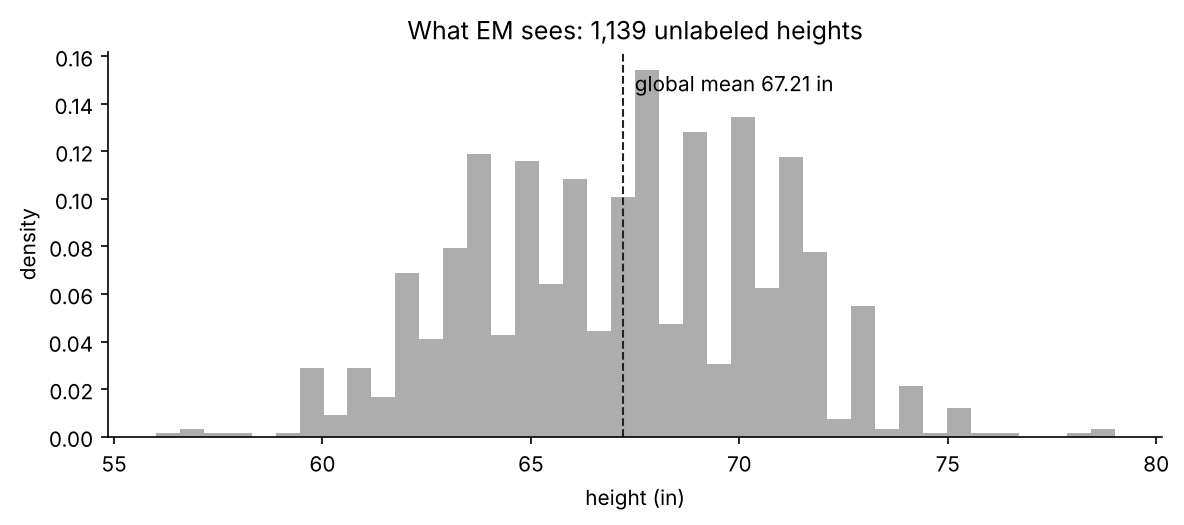

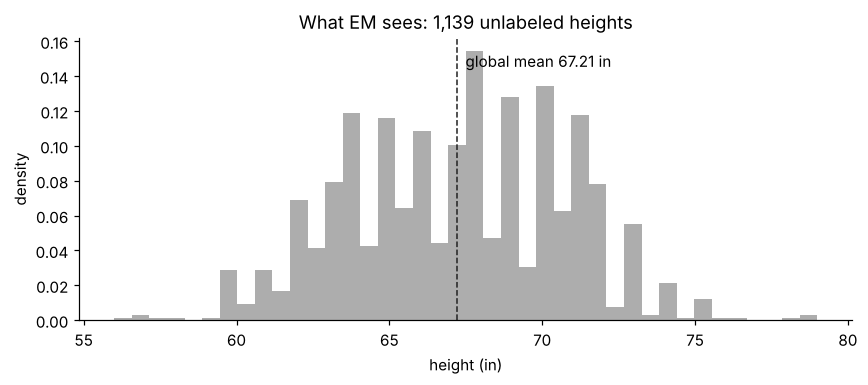

In [3]:
display(Image(plots.plot_raw(x)))

## 1. Should we just cut at the global mean, split into two piles, and take each pile's mean?
**No.** Here is what that does to this data:

         mean-split pile 1  TRUE children  mean-split pile 2  TRUE fathers
mean               64.2600        66.7500            70.2100       69.3200
std dev             2.0400         3.5800             1.8900        2.6400
count             575.0000       934.0000           564.0000      205.0000

cut = 67.21 in   |   accuracy vs true labels: 60.8%


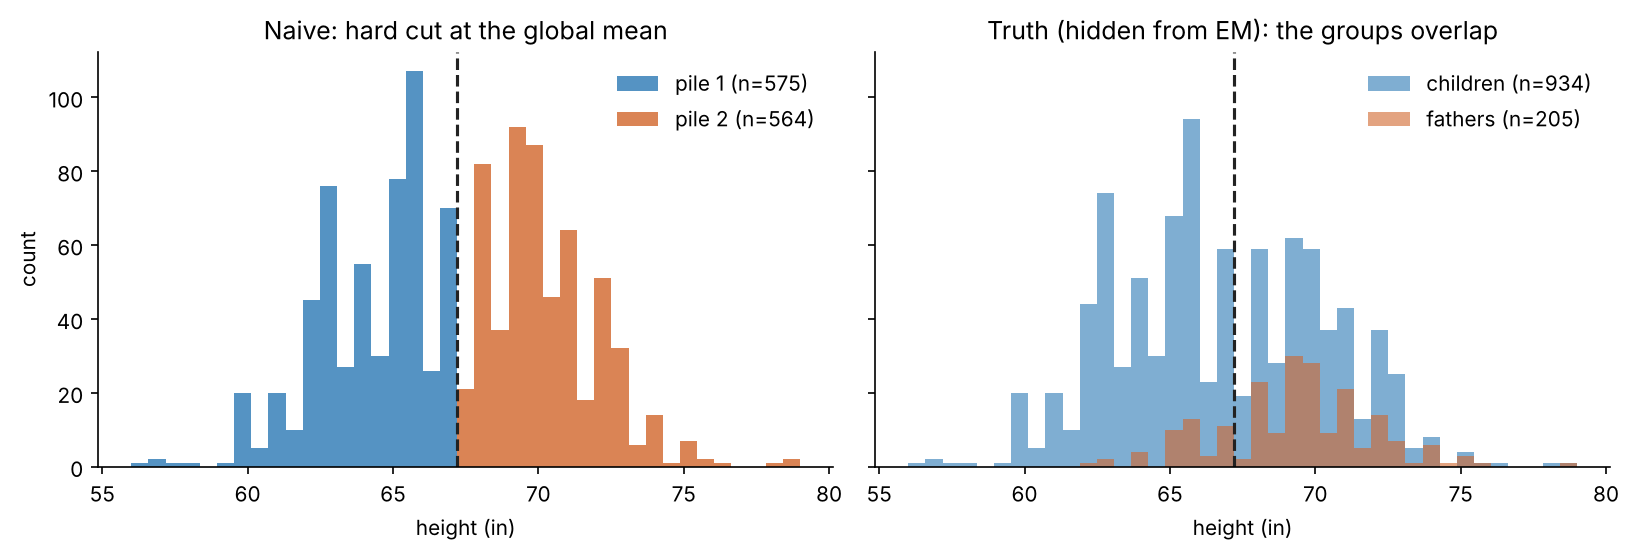

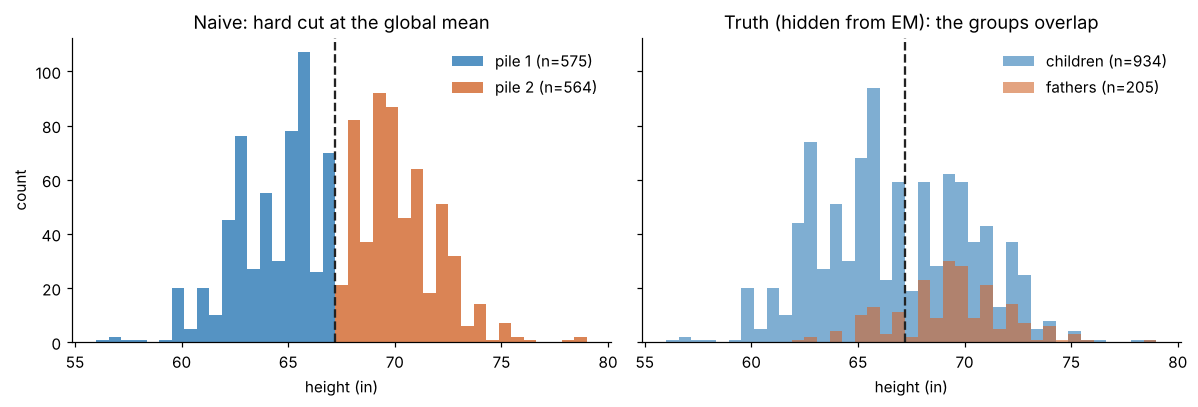

In [4]:
ms = mean_split(x)
truth = dict(mu=(x[y_true==0].mean(), x[y_true==1].mean()), sd=(x[y_true==0].std(), x[y_true==1].std()),
             n=((y_true==0).sum(), (y_true==1).sum()))
print(pd.DataFrame({
    "mean-split pile 1": [ms["mu"][0], ms["sd"][0], ms["n"][0]],
    "TRUE children":     [truth["mu"][0], truth["sd"][0], truth["n"][0]],
    "mean-split pile 2": [ms["mu"][1], ms["sd"][1], ms["n"][1]],
    "TRUE fathers":      [truth["mu"][1], truth["sd"][1], truth["n"][1]],
}, index=["mean", "std dev", "count"]).round(2))
print(f"\ncut = {ms['cut']:.2f} in   |   accuracy vs true labels: {accuracy((x >= ms['cut']).astype(int), y_true):.1%}")
display(Image(plots.plot_mean_split(x, y_true, ms)))

**Why it fails (talking points, each backed by the numbers above):**
1. **The cut is in the wrong place.** The global mean is a weighted average of the two groups. There are 4.5× more children than fathers, so the mean (67.21 in) is pulled toward the children. It is not the point where the two populations meet.
2. **Overlap means guaranteed misclassification.** Any child taller than 67.21 in is labeled a father, and any father shorter than that is labeled a child. In Galton's data many sons are taller than their fathers, so a single cut cannot be right.
3. **Truncation biases every estimate.** Cutting a bell curve in half pushes each pile's mean away from the cut (64.26 vs. the true 66.75 for children) and shrinks the spread (σ ≈ 2.0 vs. the true 3.58). The piles also come out roughly 50/50, when the true split is 82/18.
4. **Hard assignment discards uncertainty.** A 67.0 in person and a 58 in person each count as 100% "child". EM gives each point a **responsibility**, P(child | x), so a point near the boundary contributes about half to each component. That keeps the estimates unbiased and lets us report how confident we are.

The mean split is acceptable as a *starting guess* for EM (Section 4 tests that). It is a poor *final answer*.

## 2. The EM algorithm
Model: $\;p(x) = \pi_1\,\mathcal N(x\mid\mu_1,\sigma_1^2) + \pi_2\,\mathcal N(x\mid\mu_2,\sigma_2^2),\qquad \mathcal N(x\mid\mu,\sigma^2)=\frac{1}{\sqrt{2\pi\sigma^2}}e^{-(x-\mu)^2/2\sigma^2}$

Six parameters to learn: two **means**, two **variances**, two **mixing weights** ($\pi_1+\pi_2=1$).

| Step | What happens | Formula |
|---|---|---|
| **Init** | Means at the 25th/75th percentile, both variances = global variance, $\pi=(0.5,0.5)$ | `init_params` |
| **E-step** | Soft-assign every point: how responsible is each component for it? (Bayes' rule) | $r_{ik}=\dfrac{\pi_k\mathcal N(x_i\mid\mu_k,\sigma_k^2)}{\sum_j \pi_j\mathcal N(x_i\mid\mu_j,\sigma_j^2)}$ |
| **M-step** | Re-estimate parameters, using $r_{ik}$ as fractional counts | $N_k=\sum_i r_{ik},\;\; \mu_k=\frac{\sum_i r_{ik}x_i}{N_k},\;\; \sigma_k^2=\frac{\sum_i r_{ik}(x_i-\mu_k)^2}{N_k},\;\; \pi_k=\frac{N_k}{N}$ |
| **Check** | Log-likelihood | $\ell=\sum_i \log \sum_k \pi_k\mathcal N(x_i\mid\mu_k,\sigma_k^2)$ |
| **Stop** | When $\lvert\ell_t-\ell_{t-1}\rvert < 10^{-6}$ | EM guarantees $\ell$ never decreases |

The M-step is the mean-split method done properly: a weighted average where each point's weight is its probability of belonging, not a 0/1 pile label.

In [5]:
import inspect, em_gmm
for f in (em_gmm.gaussian_pdf, em_gmm.e_step, em_gmm.m_step, em_gmm.log_likelihood, em_gmm.fit_em):
    print(inspect.getsource(f))

def gaussian_pdf(x, mu, var):
    """N(x | mu, var). Broadcasts: x shape (n,1) against mu/var shape (k,) -> (n,k)."""
    return np.exp(-((x - mu) ** 2) / (2 * var)) / np.sqrt(2 * np.pi * var)

def e_step(x, p):
    """Soft assignment: each point gets a probability of belonging to each component."""
    wd = weighted_densities(x, p)
    return wd / wd.sum(axis=1, keepdims=True)

def m_step(x, r):
    """Re-estimate parameters using responsibilities as fractional counts."""
    n_k = r.sum(axis=0)
    mu = (r * x[:, None]).sum(axis=0) / n_k
    var = (r * (x[:, None] - mu) ** 2).sum(axis=0) / n_k
    return GMMParams(mu, np.maximum(var, VAR_FLOOR), n_k / len(x))

def log_likelihood(x, p):
    return float(np.sum(np.log(weighted_densities(x, p).sum(axis=1))))

def fit_em(x, init="quantile", tol=1e-6, max_iter=500):
    p = init_params(x, init) if isinstance(init, str) else init
    history = [dict(iteration=0, **p.as_row(), log_likelihood=log_likelihood(x, p))]
    for it in range(1, max

## 3. Tracking table — initialization and first two iterations

In [6]:
result = fit_em(x, init="quantile")
table = result.table(3).rename(columns={
    "mu1": "μ1 (Children)", "mu2": "μ2 (Fathers)", "var1": "σ1²", "var2": "σ2²",
    "pi1": "π1", "pi2": "π2", "log_likelihood": "Log-Likelihood"})
table.index = ["0 (Initialization)", "1", "2"]
table

,μ1 (Children),μ2 (Fathers),σ1²,σ2²,π1,π2,Log-Likelihood
0 (Initialization),64.5000,70.0000,12.7241,12.7241,0.5000,0.5000,-3119.8222
1,65.2205,69.2054,9.0603,8.4468,0.5011,0.4989,-3057.9135
2,65.1609,69.2600,8.9420,8.1040,0.5005,0.4995,-3056.9719


In [7]:
print(f"Converged: {result.converged} after {len(result.history)-1} iterations")
print("Final parameters:")
result.table().tail(1)

Converged: True after 319 iterations
Final parameters:


,mu1,mu2,var1,var2,pi1,pi2,log_likelihood
iteration,,,,,,,
319,64.1772,69.5186,5.3024,6.0410,0.4325,0.5675,-3046.9895


**Reading the table:** iteration 1 does most of the work. Log-likelihood jumps by about 62, the two variances shrink from the shared 12.72 to about 9, and the means move apart. Iteration 2 only adds about 0.9. The remaining iterations keep separating the components until the change in ℓ drops below 10⁻⁶.

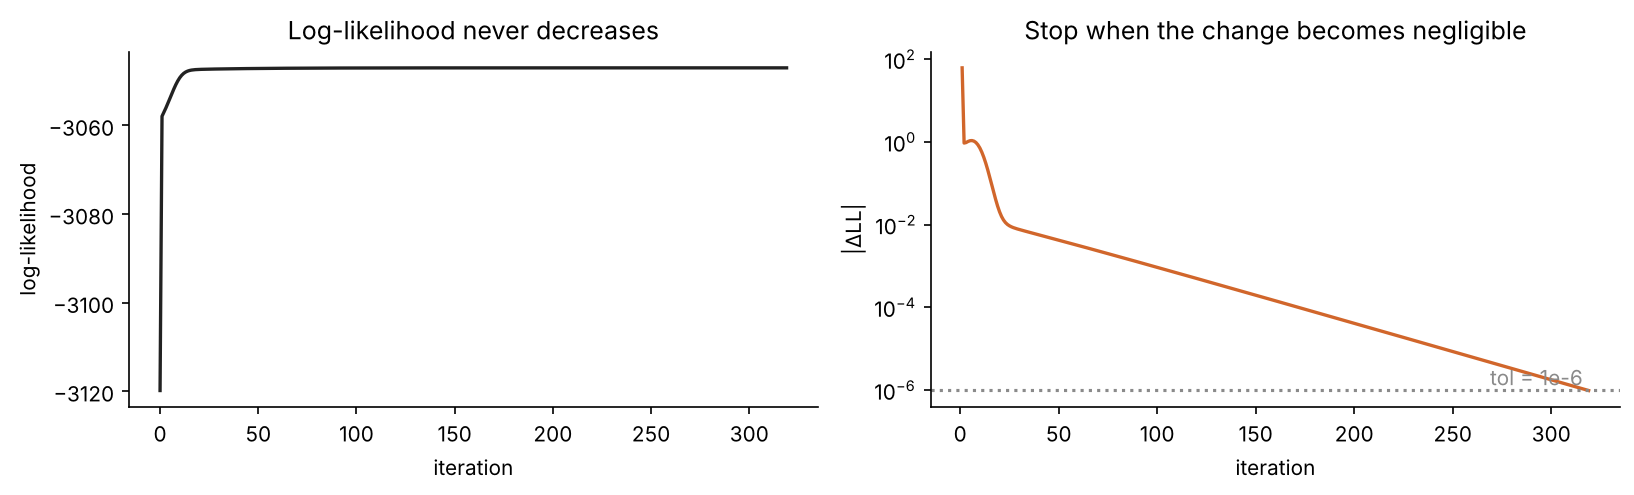

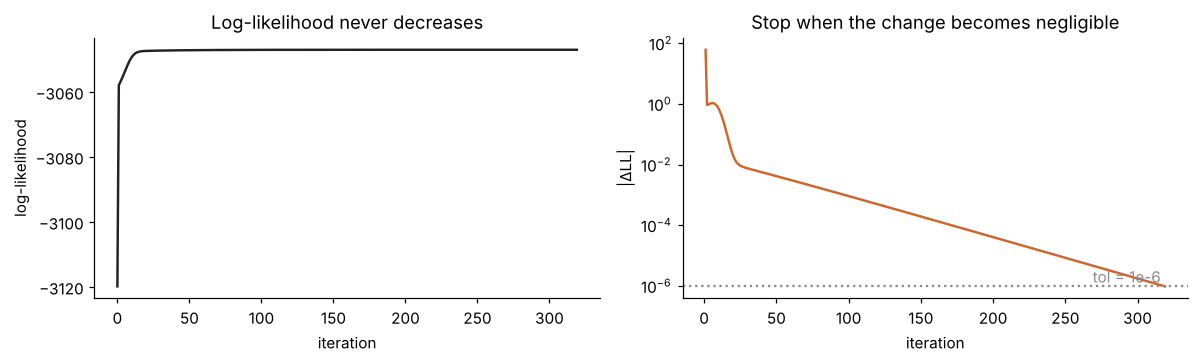

In [8]:
display(Image(plots.plot_convergence(result.history)))

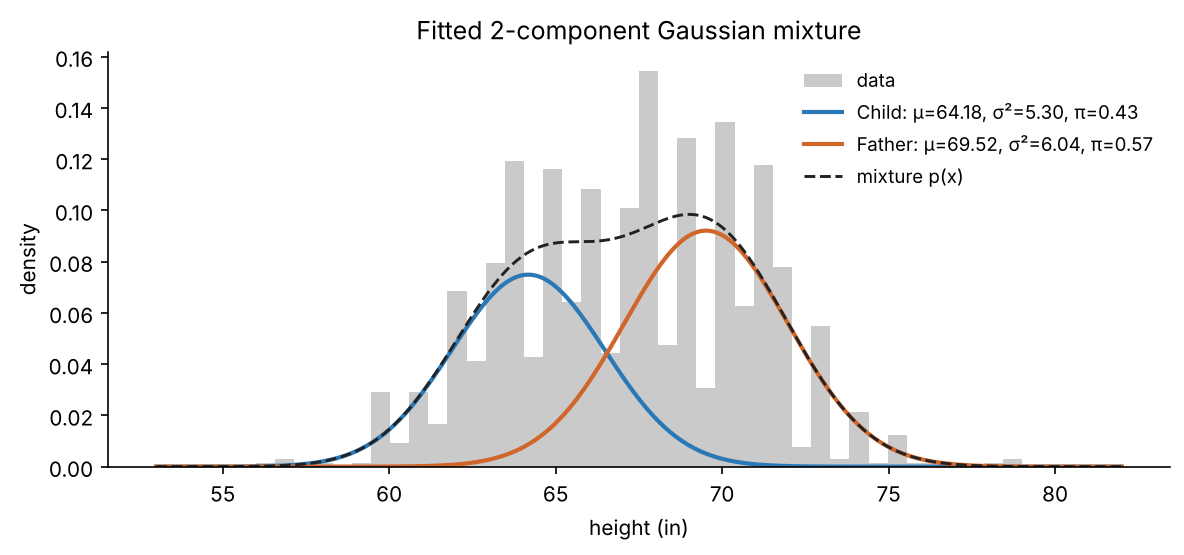

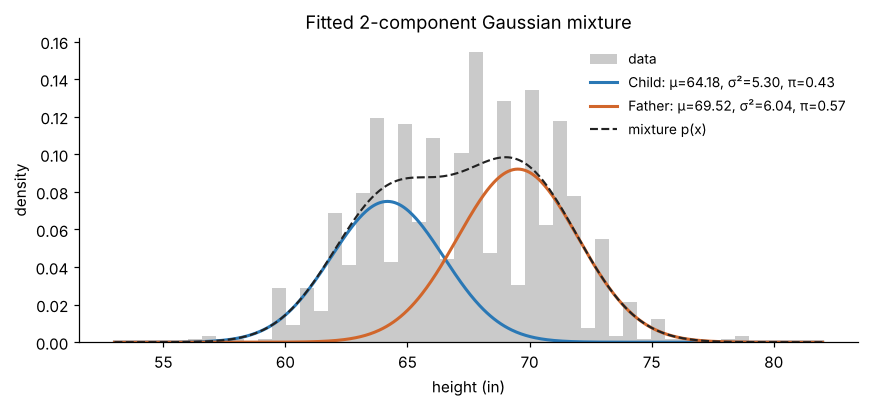

In [9]:
display(Image(plots.plot_fit(x, result.params)))

## 4. Live classification demo
**Coach's test height:** set `TEST_HEIGHT` (and `UNIT` if it is given in cm), then re-run the cell. The output is the E-step applied to a single point: Bayes' rule with the fitted parameters.
From a terminal you can also run `python demo.py 70` or `python demo.py 178 --unit cm`.

Test height: 68.0 in  ->  68.00 in
  pi_1*N(x|mu_1,var_1) [Child ] = 1.888745e-02
  pi_2*N(x|mu_2,var_2) [Father] = 7.610948e-02
  evidence p(x)                      = 9.499693e-02
  P(Child)   = 0.198822  (19.88%)
  P(Father)  = 0.801178  (80.12%)
  -> classified as: Father


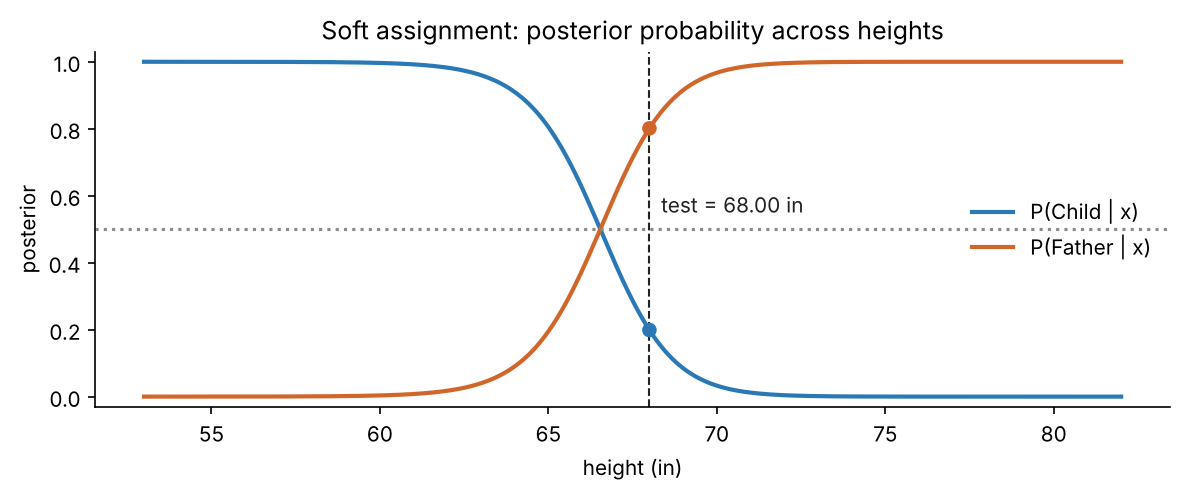

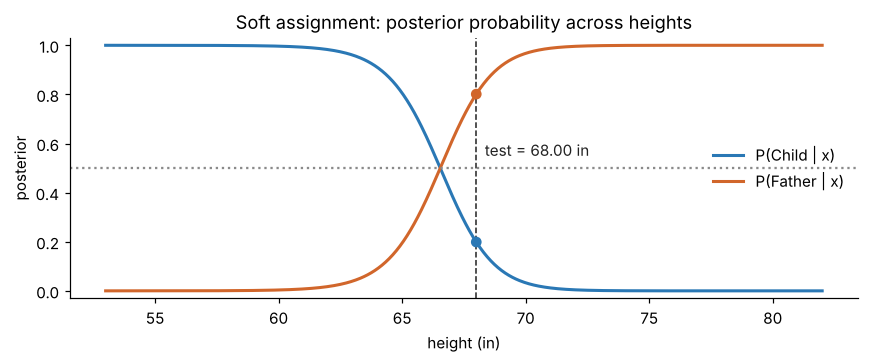

In [10]:
TEST_HEIGHT = 68.0     # <-- coach's number goes here
UNIT = "in"            # "in" or "cm"

post = print_classification(TEST_HEIGHT, result.params, UNIT)
h_in = TEST_HEIGHT / 2.54 if UNIT == "cm" else TEST_HEIGHT
display(Image(plots.plot_posterior(x, result.params, test_in=h_in)))

In [11]:
# The same function across a range, for Q&A
pd.DataFrame([{"height (in)": h, **classify(h, result.params)} for h in [60, 63, 65, 66, 67, 68, 70, 73]]).set_index("height (in)")

,P(Child),P(Father)
height (in),,
60,0.9965,0.0035
63,0.9601,0.0399
65,0.8053,0.1947
66,0.6236,0.3764
67,0.3934,0.6066
68,0.1988,0.8012
70,0.0328,0.9672
73,0.0014,0.9986


**The decision boundary** is where the curves cross, around 66.5 in. That is close to the global mean, but EM arrives at it from the fitted densities rather than from a raw average. Points near the boundary get probabilities near 50/50, and that uncertainty is the information a hard cut throws away.

## 5. Honest evaluation: what did EM actually find?
We now use the hidden labels. EM's components are mathematically optimal (the highest log-likelihood we found), but they do **not** line up with "children vs. fathers":

EM accuracy vs generation labels:      56.5%
Mean-split accuracy vs generation labels: 60.8%

True mixing weights: children 0.82 / fathers 0.18
EM mixing weights:   comp1    0.43 / comp2   0.57

Children by sex:
           mean    std  count
gender                      
female 64.1000 2.3600    453
male   69.2300 2.6200    481


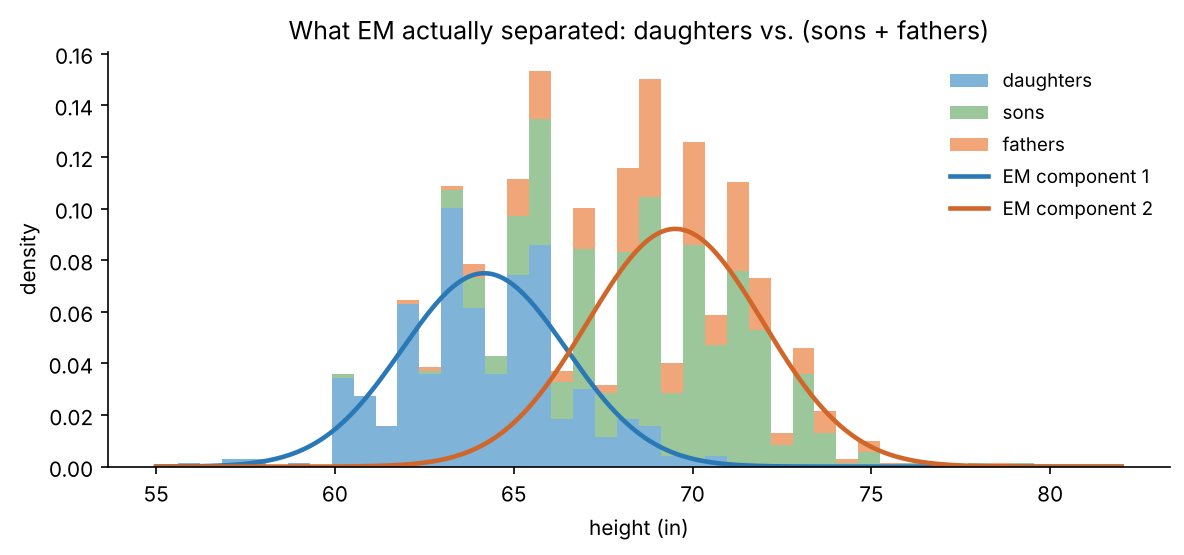

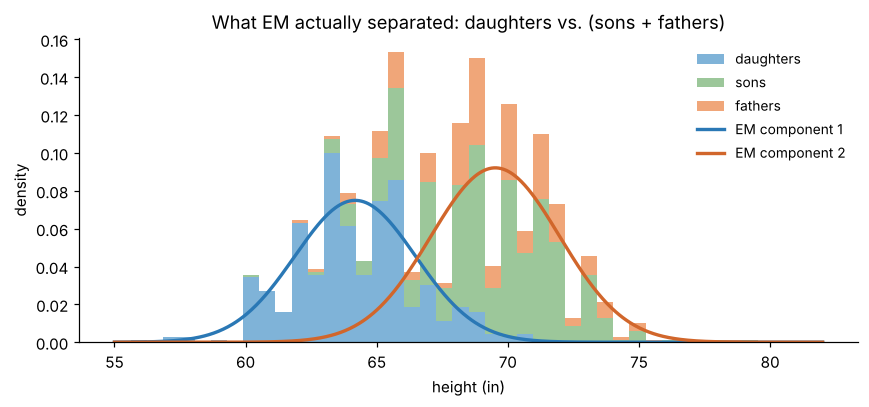

In [12]:
pred = e_step(x, result.params).argmax(axis=1)
print(f"EM accuracy vs generation labels:      {accuracy(pred, y_true):.1%}")
print(f"Mean-split accuracy vs generation labels: {accuracy((x >= x.mean()).astype(int), y_true):.1%}")
print(f"\nTrue mixing weights: children {np.mean(y_true==0):.2f} / fathers {np.mean(y_true==1):.2f}")
print(f"EM mixing weights:   comp1    {result.params.pi[0]:.2f} / comp2   {result.params.pi[1]:.2f}")
kids = df.groupby('gender').childHeight.agg(['mean', 'std', 'count']).round(2)
print("\nChildren by sex:\n", kids)
display(Image(plots.plot_hidden_structure(df, result.params)))

**Key finding (say this in the presentation):**
* The "children" group is itself **bimodal**: daughters average 64.1 in and sons average 69.2 in. That is the same as the fathers (69.3 in).
* EM's component 1 (μ≈64.2) is essentially **the daughters**. Component 2 (μ≈69.5) is **sons plus fathers**. The strongest two-group structure in this data is **sex, not generation**, and EM found it.
* So "P(Child)" from our model really means "P(belongs to the shorter population)". A 70-in son gets classified as a father. That is not a bug in EM: our model assumes each population is a single Gaussian, and the children are not.
* **"So is the mean split better (60.8% vs. 56.5%)?"** No. Accuracy is misleading here because 82% of points are children: a model that always says "child" scores 82%. Neither method recovers generation. What matters is that EM's parameters describe two real, well-fitting populations with honest probabilities, while the mean split's statistics are truncation artefacts.
* **Fixes, if we had more time:** three components (daughters / sons / fathers), comparing daughters with mothers only, or a semi-supervised EM that uses a few known labels to anchor the components.

## 6. Is the implementation correct?

In [13]:
# (a) Initialisation sensitivity: EM finds a local optimum, so compare starting points
for init in ["quantile", "mean_split"]:
    r = fit_em(x, init=init)
    print(f"{init:11s} -> mu={r.params.mu.round(3)}, var={r.params.var.round(3)}, "
          f"pi={r.params.pi.round(3)}, LL={r.history[-1]['log_likelihood']:.4f}, iters={len(r.history)-1}")

# (b) Monotonic log-likelihood (EM's guarantee)
ll = np.array([h["log_likelihood"] for h in result.history])
print("\nLog-likelihood ever decreased?", bool(np.any(np.diff(ll) < -1e-9)))

# (c) Recovery on synthetic data with KNOWN parameters
rng = np.random.default_rng(42)
xs = np.concatenate([rng.normal(60, 2, 700), rng.normal(72, 3, 300)])
p = fit_em(xs).params
print(f"\nSynthetic truth: mu=(60, 72)  var=(4, 9)  pi=(0.70, 0.30)")
print(f"EM recovered:    mu=({p.mu[0]:.2f}, {p.mu[1]:.2f})  var=({p.var[0]:.2f}, {p.var[1]:.2f})  pi=({p.pi[0]:.2f}, {p.pi[1]:.2f})")

quantile    -> mu=[64.177 69.519], var=[5.302 6.041], pi=[0.432 0.568], LL=-3046.9895, iters=319
mean_split  -> mu=[64.177 69.519], var=[5.302 6.041], pi=[0.432 0.568], LL=-3046.9895, iters=309

Log-likelihood ever decreased? False

Synthetic truth: mu=(60, 72)  var=(4, 9)  pi=(0.70, 0.30)
EM recovered:    mu=(59.93, 72.04)  var=(3.89, 8.51)  pi=(0.70, 0.30)


Both starting points converge to the same optimum, ℓ never decreases, and on synthetic data with known answers EM recovers the true parameters. The mismatch in Section 5 is a fact about Galton's data, not an error in the code.

## Summary
| Question | Answer |
|---|---|
| Split at the global mean? | No. The cut is biased by group sizes, overlapping points are misclassified, pile statistics are truncated, and all uncertainty is lost. |
| E-step | Bayes' rule gives each point a soft responsibility for each component. |
| M-step | Responsibility-weighted means, variances, and mixing weights. |
| When to stop | When the log-likelihood change is below 10⁻⁶ (it never decreases). |
| Finding | EM cleanly separates a short and a tall population, but in Galton's data that split is daughters vs. sons + fathers, because sex drives height more than generation does. |